In [14]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Mall_Customers.csv")
df.head(2)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df = df.drop("CustomerID", axis = 1)
df.sample(3)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
141,Male,32,75,93
36,Female,42,34,17
92,Male,48,60,49


In [7]:
X = df.drop(["Gender","Age"], axis = 1)
X.head()


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [8]:
scalar = StandardScaler()
x_scaled = scalar.fit_transform(X)


In [9]:
model = DBSCAN(eps=10, min_samples=4)# min_samples could be defined as 2x the number of col to form meaning clusters 
# to calculate the best eps epsilon evalue you need to calculate the k distance elbow method    where k = min_samples we have to sort the distances and plot them 

model.fit(X)
model.labels_

array([ 0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0, -1,  0,  0,  0,  0,  0,
        0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  1,  0,  1,  0,  1,  2,  1,  2,  1,  0,  1,  2,  1,
        2,  1,  2,  1,  2,  1,  0,  1,  2,  1,  0,  1,  2,  1,  2,  1,  2,
        1,  2,  1,  2,  1,  2,  1,  0,  1,  2,  1,  2,  1,  2,  1,  2,  1,
        2,  1,  2,  1,  2,  1,  2,  1,  2,  1,  2,  1,  2,  1, -1,  1,  2,
       -1,  2,  1,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1])

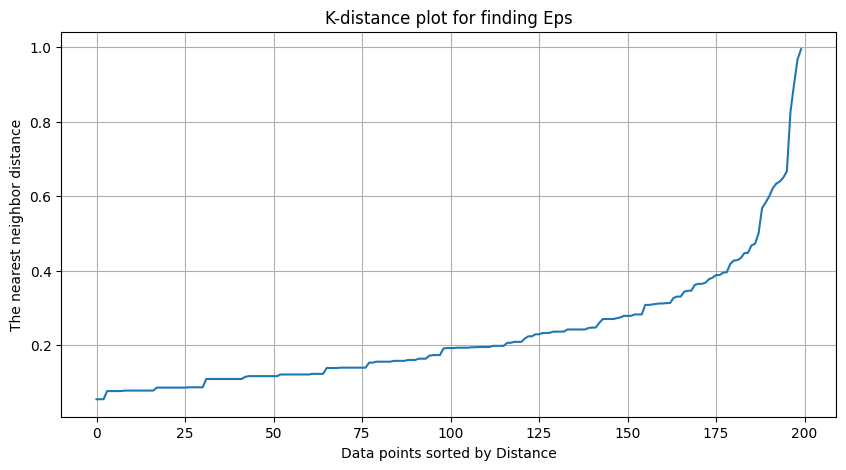

In [12]:
#calculating the Optimum value  eps

# to do this we need to import thr NearestNeighbours class from sklearn

from sklearn.neighbors import NearestNeighbors
import numpy as np

# initialze the engine
# min_samples  = n_neighbors  = 2*col = 4
neighbors = NearestNeighbors(n_neighbors= 4) # Creates a data Structure for fast distance calculation 
neighbors_fit = neighbors.fit(x_scaled) # create a map/tree (BallTree) to quickly identify neighbors
dist,index = neighbors_fit.kneighbors(x_scaled) # this Does the heavy lifting iterates through each datapoint and calculates the distance between itself 1stcol and the other neighbors also returns the index of the respective points


sorted_dist = np.sort(dist[:,-1])

plt.figure(figsize=(10,5))
plt.plot(sorted_dist, linestyle = "-")
plt.xlabel("Data points sorted by Distance")
plt.ylabel("The nearest neighbor distance")
plt.title("K-distance plot for finding Eps")
plt.grid()

plt.show()

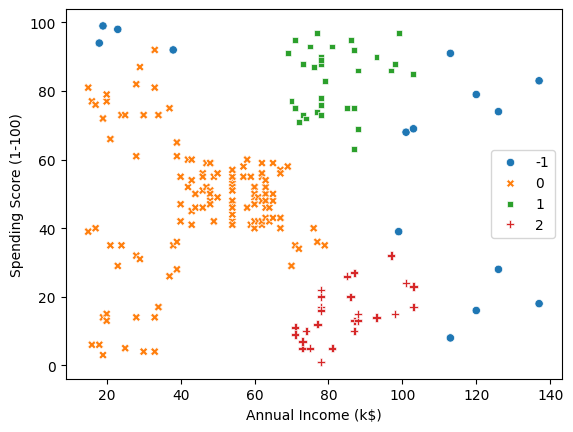

In [26]:
model = DBSCAN(eps =0.375, min_samples=4)
model.fit(x_scaled)
sns.scatterplot(x = df["Annual Income (k$)"], y = df["Spending Score (1-100)"], hue=model.labels_, palette="tab10", style=model.labels_ )
plt.show()

In [27]:
df["Cluster"] = model.labels_

In [29]:
col_to_profile = ["Age", "Spending Score (1-100)", "Annual Income (k$)"]

columns_profiles = df[col_to_profile].groupby(df["Cluster"]).mean()

print("Column profiles ")
print(columns_profiles)


Column profiles 
               Age  Spending Score (1-100)  Annual Income (k$)
Cluster                                                       
-1       34.000000               63.733333           92.866667
 0       40.528000               47.640000           46.224000
 1       32.727273               83.000000           81.060606
 2       41.259259               14.444444           83.925926


In [ ]:
#Inference 
# Outlier -1 : They have the highest Annual Income and mid spending score  
# Cluster 0 : They are the regular people with both spending score and annual income minimum
# Cluster 1 : They are top spender with a high-mid income and the youngest of all 
# Cluster 2 : They are Adult-Old category with the minimum spendin score and the second highest annual income

In [30]:
df.to_csv("Labeled_Mall_Customers.csv")